In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew

Distribution Summary Statistics:
 department            HR             IT
count         100.000000     100.000000
mean        55178.436696   83961.534826
std          7629.351729    9081.684280
min         39649.830278   58802.548959
25%         48554.715815   78990.943295
50%         55672.857360   83730.437082
75%         59305.363581   89059.520520
max         76761.353333  103522.781845


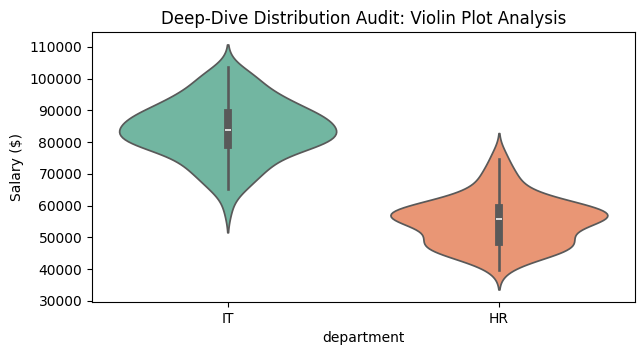

In [9]:
np.random.seed(42)
df_dist = pd.DataFrame({
	'department': ['IT'] * 100 + ['HR'] * 100,
	'salary':np.concatenate([np.random.normal(85000,10000,100), np.random.normal(55000,8000,100)])
})
print("Distribution Summary Statistics:\n", df_dist.groupby('department')['salary'].describe().T)

# Visualization
plt.figure(figsize=(7, 3.5))
# sns.violinplot(x='department', y='salary', data=df_dist, palette='Set2') # old with warning
sns.violinplot(x='department', y='salary', hue='department', data=df_dist, palette='Set2')
plt.title('Deep-Dive Distribution Audit: Violin Plot Analysis')
plt.ylabel('Salary ($)')
plt.show()

Correlation Matrix:
            feature_a  feature_b
feature_a   1.000000  -0.136422
feature_b  -0.136422   1.000000


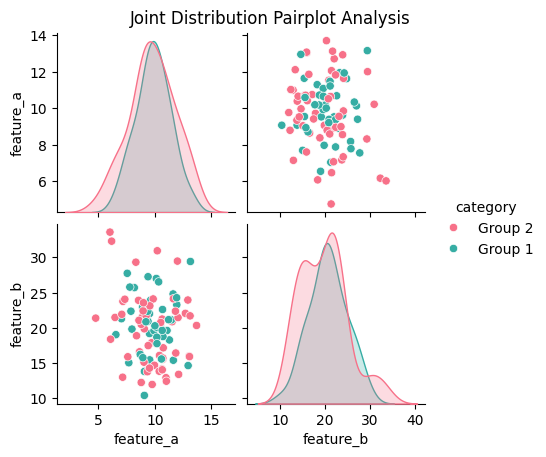

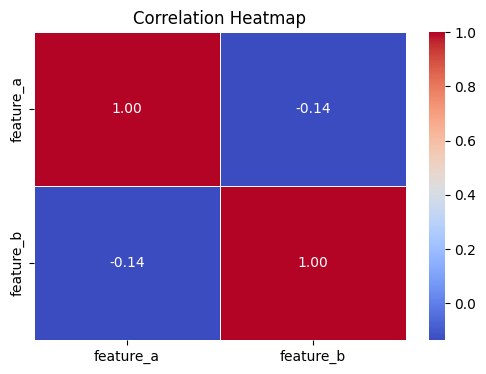

In [15]:
np.random.seed(42)
df_joint = pd.DataFrame({
	'feature_a': np.random.normal(10, 2, 100),
    'feature_b': np.random.normal(20, 5, 100),
    'category': np.random.choice(['Group 1', 'Group 2'], 100)
})

# Correlation matrix check
print("Correlation Matrix:\n", df_joint[['feature_a', 'feature_b']].corr())

# Visualization
sns.pairplot(df_joint, hue='category', height=2.2, palette='husl')
plt.suptitle('Joint Distribution Pairplot Analysis', y=1.02)
plt.show()

plt.figure(figsize=(6, 4))
sns.heatmap(
    df_joint[['feature_a', 'feature_b']].corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap')
plt.show()

In [16]:
df_breakdown = pd.DataFrame({
    'region': ['North', 'North', 'South', 'South', 'East', 'East'],
    'sales': [250, 300, 450, 400, 150, 180]
})

segment_summary = df_breakdown.groupby('region')['sales'].agg(['mean', 'median', 'std']).reset_index()
print(
    "Segment Breakdown Summary:\n",
    segment_summary.to_string(index=False),
)

Segment Breakdown Summary:
 region  mean  median       std
  East 165.0   165.0 21.213203
 North 275.0   275.0 35.355339
 South 425.0   425.0 35.355339


Original Skewness: 1.4409012249947706
Log-Transformed Skewness: 0.33730012283200667


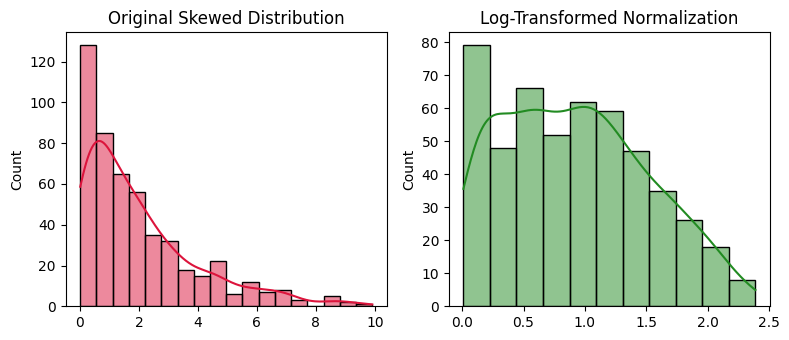

In [ ]:
np.random.seed(42) 
skewed_data = np.random.exponential(scale=2.0, size=500) 
log_transformed = np.log1p(skewed_data)    #log1p function is used to handle infinite exception

print("Original Skewness:", skew(skewed_data)) 
print("Log-Transformed Skewness:", skew(log_transformed)) 

# Visualization 
fig, axes = plt.subplots(1, 2, figsize=(8, 3.5)) 
sns.histplot(skewed_data, kde=True, ax=axes[0], color='crimson') 
axes[0].set_title('Original Skewed Distribution') 
sns.histplot(log_transformed, kde=True, ax=axes[1], color='forestgreen') 
axes[1].set_title('Log-Transformed Normalization') 
plt.tight_layout() 
plt.show() 